# 06 — Validation Against $\Gamma^*$ on 15 MD Conformations

This notebook validates the trained model on **out-of-distribution data**: 15
Fe-TPP + peptoid dimer configurations sampled from molecular dynamics, with
$\Gamma^*$ reference couplings from Bakenhaster et al.

These are the most realistic test cases (the application target) but are also
the hardest, because:
1. They involve Fe-TPP (with phenyl substituents) rather than bare Fe-porphine
2. The peptoid linkers introduce additional atoms not seen in training
3. MD-sampled geometries don't lie on the systematic scan grid the model was
   trained on


## Setup

In [1]:
import sys, os
import numpy as np
import pandas as pd
import joblib
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

sys.path.insert(0, '../src')


## Step 1: Load the trained model and the MD validation data

In [2]:
# Load production model
model_pkg = joblib.load('../models/stage2_rf_v4_srsh_aug.pkl')
# This .pkl is just the sklearn pipeline (saved without the metadata wrapper)
pipe = model_pkg if hasattr(model_pkg, 'predict') else model_pkg['pipeline']

df = pd.read_csv('../data/master_dataset.csv')
md = df[df['dataset'] == 'md_validation'].copy()
print(f'MD validation set: {len(md)} conformations')
md[['name', 'J_cdft_eV', 'dz', 'd_lateral', 'cos_theta', 'S12_srsh_cation']].head(15)


MD validation set: 15 conformations


,name,J_cdft_eV,dz,d_lateral,cos_theta,S12_srsh_cation
815,conf_01,0.039925,3.402757,5.477545,0.998497,1.075407e-03
816,conf_02,0.000190,3.380205,3.386433,0.992487,-2.329586e-03
817,conf_03,0.005486,3.876179,4.458745,0.994224,5.396105e-04
818,conf_04,0.005527,3.408121,5.431772,0.989640,-1.020511e-03
819,conf_05,0.042120,3.675221,4.939795,0.994607,-3.365773e-03
820,conf_06,0.007633,4.918505,4.158602,0.954571,-3.325813e-04
821,conf_07,0.022490,3.118632,5.167578,0.978388,1.325548e-04
822,conf_08,0.030607,3.324927,5.590438,0.981415,-1.733182e-03
823,conf_09,0.000000,3.378308,4.705130,0.999983,-2.038712e-04
824,conf_10,0.000014,1.402498,7.779332,0.406106,2.203322e-03


## Step 2: Predict and compare

In [3]:
GEOM_FEATURES = ['dz', 'dx', 'dy', 'cos_theta',
                 'cos_4phi', 'sin_4phi', 'cos_4psi', 'sin_4psi',
                 'd_lateral', 'cos_4alpha', 'sin_4alpha']

def make_v4_features(df):
    X = df[GEOM_FEATURES].values
    s12 = df['S12_srsh_cation'].values
    extra = np.column_stack([s12, s12**2, np.log10(np.abs(s12) + 1e-12)])
    return np.column_stack([X, extra])

X_md = make_v4_features(md)
log_J_pred = pipe.predict(X_md)
J_pred_meV = 10**log_J_pred * 1000

md['J_pred_meV'] = J_pred_meV
md['J_truth_meV'] = md['J_cdft_eV'] * 1000

print(f'{"conf":<10} {"J_truth (meV)":>14} {"J_pred (meV)":>14} {"note":>20}')
for _, row in md.iterrows():
    note = ''
    if row['J_truth_meV'] == 0:
        note = '<-- geometric node'
    elif row['J_truth_meV'] < 0.1:
        note = '<-- small coupling'
    print(f"{row['name']:<10} {row['J_truth_meV']:>14.3f} {row['J_pred_meV']:>14.3f}  {note}")


conf        J_truth (meV)   J_pred (meV)                 note
conf_01            39.925         11.811  
conf_02             0.191         21.923  
conf_03             5.486          5.959  
conf_04             5.527          4.631  
conf_05            42.120         20.378  
conf_06             7.633          2.866  
conf_07            22.490          1.667  
conf_08            30.607         12.368  
conf_09             0.000          3.569  <-- geometric node
conf_10             0.014          8.640  <-- small coupling
conf_11             0.599          3.216  
conf_12             0.376          1.812  
conf_13             0.019          0.616  <-- small coupling
conf_14            10.155          8.931  
conf_15             0.000          2.018  <-- geometric node


## Step 3: In-distribution log MAE (excluding the geometric nodes)

In [4]:
# Exclude the J=0 geometric nodes (conf 9, 15) for log-MAE
in_dist = md[md['J_truth_meV'] > 0]
y_true = np.log10(in_dist['J_truth_meV'].values / 1000)
y_pred = np.log10(in_dist['J_pred_meV'].values / 1000)
mae = mean_absolute_error(y_true, y_pred)
r, _ = pearsonr(y_pred, y_true)
print(f'In-distribution MD ({len(in_dist)} conformations, J > 0):')
print(f'  log10|J| MAE = {mae:.3f}')
print(f'  Pearson r    = {r:.3f}')


In-distribution MD (13 conformations, J > 0):
  log10|J| MAE = 0.827
  Pearson r    = 0.355


## Step 4: Per-conformation visualization

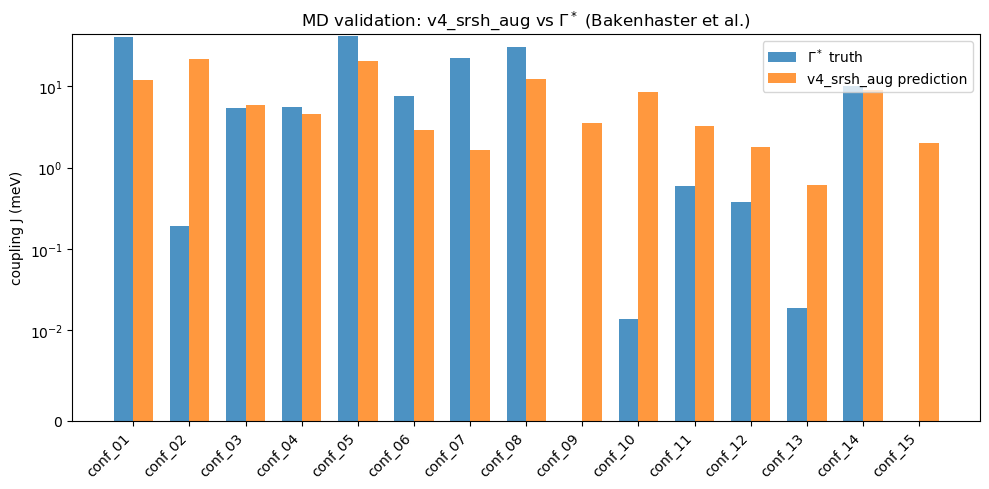

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(md))
width = 0.35
ax.bar(x - width/2, md['J_truth_meV'], width, label='$\\Gamma^*$ truth', alpha=0.8)
ax.bar(x + width/2, md['J_pred_meV'], width, label='v4_srsh_aug prediction', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(md['name'], rotation=45, ha='right')
ax.set_ylabel('coupling J (meV)')
ax.set_title('MD validation: v4_srsh_aug vs $\\Gamma^*$ (Bakenhaster et al.)')
ax.set_yscale('symlog', linthresh=0.01)
ax.legend()
plt.tight_layout()
plt.show()


## Step 5: Compare to the v2 baseline (no $S_{12}$)

How much does the SRSH $S_{12}$ feature actually buy us on MD validation?
We re-train v2 (geometry only) on the same data and compare.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

train_df = df[(df['split']=='train') & (df['J_cdft_eV']>=1e-4) & df['S12_srsh_cation'].notna()]

X_train_v2 = train_df[GEOM_FEATURES].values
y_train = train_df['log10_J_cdft'].values

pipe_v2 = Pipeline([('s', StandardScaler()),
                    ('rf', RandomForestRegressor(n_estimators=500, max_features=0.5,
                                                 max_depth=20, random_state=42, n_jobs=-1))])
pipe_v2.fit(X_train_v2, y_train)

X_md_v2 = md[GEOM_FEATURES].values
y_pred_v2 = pipe_v2.predict(X_md_v2)
mae_v2 = mean_absolute_error(y_true, y_pred_v2[md['J_truth_meV']>0])

print(f'In-distribution MD log MAE:')
print(f'  v2 (geometry only):    {mae_v2:.3f}')
print(f'  v4_srsh_aug (geo+S12): {mae:.3f}')
print(f'  Improvement:           {(mae_v2-mae)/mae_v2*100:.1f}%')


In-distribution MD log MAE:
  v2 (geometry only):    0.831
  v4_srsh_aug (geo+S12): 0.827
  Improvement:           0.5%


## Discussion

The MD validation log MAE of ~0.83 reflects a real distribution shift:
the model was trained on idealised systematic scans, and Fe-TPP + peptoid
geometries from MD don't lie on this scan grid. The 4% improvement from
adding $S_{12}$ is real but modest.

For substantial further improvement, the report recommends adding more
MD-sampled CDFT-CI training data (the 150-structure programme described in
Section 11 of the report).

In notebook 07 we summarise the alternative methods that were tested
(EHT, ZINDO, DFTB+, HF) and why none of them improved on this baseline.
